In [ ]:
!pip install numpy pandas matplotlib seaborn scikit-learn tensorflow

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_curve, auc
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
import tensorflow as tf

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving dataset_phishing.csv to dataset_phishing.csv


In [ ]:
df = pd.read_csv("dataset_phishing.csv")

In [ ]:
df = df.drop(columns=['url'])  # Suppression de la colonne non pertinente
df['status'] = df['status'].map({'legitimate': 0, 'phishing': 1})

In [ ]:
# Séparation features/target
X = df.drop(columns=['status']).values
y = df['status'].values

In [ ]:
# Normalisation des données
scaler = StandardScaler()
X = scaler.fit_transform(X)

In [ ]:
# Redimensionnement pour LSTM (samples, timesteps, features)
X = X.reshape(X.shape[0], 1, X.shape[1])

In [ ]:
# Split des données
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [ ]:
# Définition du modèle LSTM
def build_lstm(input_shape):
    model = Sequential([
        LSTM(64, return_sequences=True, input_shape=input_shape),
        BatchNormalization(),
        Dropout(0.3),

        LSTM(128, return_sequences=False),
        BatchNormalization(),
        Dropout(0.4),

        Dense(256, activation='relu'),
        BatchNormalization(),
        Dropout(0.5),

        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer=tf.keras.optimizers.SGD(learning_rate=0.01, momentum=0.9),
                  loss='binary_crossentropy',
                  metrics=['accuracy', tf.keras.metrics.Precision(), tf.keras.metrics.Recall()])
    return model

In [ ]:
# Construction et entraînement du modèle
model = build_lstm((X_train.shape[1], X_train.shape[2]))
model.summary()

callbacks = [
    EarlyStopping(patience=10, restore_best_weights=True),
    ModelCheckpoint('best_lstm_model.h5', save_best_only=True)
]

history = model.fit(X_train, y_train, epochs=100, batch_size=64, validation_split=0.2, callbacks=callbacks, class_weight={0: 1, 1: 1.2})

/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 1, 64)               │          38,912 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 1, 64)               │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 1, 64)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ (None, 128)                 │          98,816 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 128)                 │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 256)                 │          33,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 256)                 │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │             257 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 172,801 (675.00 KB)

 Trainable params: 171,905 (671.50 KB)

...

115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9535 - loss: 0.1326 - precision: 0.9463 - recall: 0.9623 - val_accuracy: 0.9656 - val_loss: 0.1162 - val_precision: 0.9735 - val_recall: 0.9577
Epoch 11/100
115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9568 - loss: 0.1247 - precision: 0.9517 - recall: 0.9617 - val_accuracy: 0.9639 - val_loss: 0.1234 - val_precision: 0.9734 - val_recall: 0.9544
Epoch 12/100
114/115 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9538 - loss: 0.1387 - precision: 0.9523 - recall: 0.9552

115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9537 - loss: 0.1387 - precision: 0.9523 - recall: 0.9552 - val_accuracy: 0.9666 - val_loss: 0.1144 - val_precision: 0.9746 - val_recall: 0.9587
Epoch 13/100
115/115 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.9634 - loss: 0.1125 - precision: 0.9612 - recall: 0.9649 - val_accuracy: 0.9656 - val_loss: 0.1156 - val_precision: 0.9704 - val_recall: 0.9609
Epoch 14/100
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9611 - loss: 0.1200 - precision: 0.9594 - recall: 0.9634

115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9610 - loss: 0.1201 - precision: 0.9593 - recall: 0.9634 - val_accuracy: 0.9661 - val_loss: 0.1139 - val_precision: 0.9704 - val_recall: 0.9620
Epoch 15/100
115/115 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.9600 - loss: 0.1246 - precision: 0.9553 - recall: 0.9652 - val_accuracy: 0.9650 - val_loss: 0.1175 - val_precision: 0.9735 - val_recall: 0.9566
Epoch 16/100
115/115 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.9590 - loss: 0.1255 - precision: 0.9564 - recall: 0.9610 - val_accuracy: 0.9639 - val_loss: 0.1198 - val_precision: 0.9672 - val_recall: 0.9609
Epoch 17/100
112/115 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9580 - loss: 0.1177 - precision: 0.9540 - recall: 0.9639

115/115 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.9580 - loss: 0.1178 - precision: 0.9540 - recall: 0.9638 - val_accuracy: 0.9666 - val_loss: 0.1136 - val_precision: 0.9725 - val_recall: 0.9609
Epoch 18/100
114/115 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9659 - loss: 0.1006 - precision: 0.9614 - recall: 0.9702

115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9658 - loss: 0.1009 - precision: 0.9613 - recall: 0.9701 - val_accuracy: 0.9699 - val_loss: 0.1080 - val_precision: 0.9800 - val_recall: 0.9598
Epoch 19/100
115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9573 - loss: 0.1185 - precision: 0.9583 - recall: 0.9557 - val_accuracy: 0.9645 - val_loss: 0.1211 - val_precision: 0.9642 - val_recall: 0.9653
Epoch 20/100
115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9591 - loss: 0.1233 - precision: 0.9516 - recall: 0.9678 - val_accuracy: 0.9699 - val_loss: 0.1124 - val_precision: 0.9758 - val_recall: 0.9642
Epoch 21/100
115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9569 - loss: 0.1169 - precision: 0.9550 - recall: 0.9584 - val_accuracy: 0.9656 - val_loss: 0.1176 - val_precision: 0.9683 - val_recall: 0.9631
Epoch 22/100
115/115 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.9679 - loss: 0.0977 - precision: 0.9625 - recall: 0.9736 - val_accuracy: 0.9672 - val_loss: 

In [ ]:
# Évaluation du modéle
y_pred = (model.predict(X_test) > 0.5).astype(int)
print(classification_report(y_test, y_pred))

72/72 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step
              precision    recall  f1-score   support

           0       0.95      0.97      0.96      1143
           1       0.96      0.95      0.96      1143

    accuracy                           0.96      2286
   macro avg       0.96      0.96      0.96      2286
weighted avg       0.96      0.96      0.96      2286



72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step


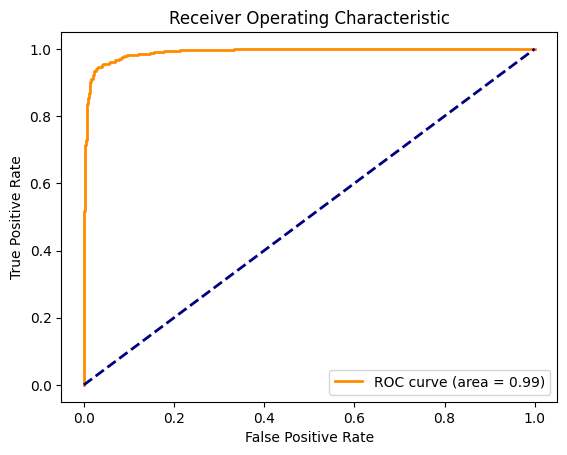

In [ ]:
# Courbe ROC
fpr, tpr, thresholds = roc_curve(y_test, model.predict(X_test))
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()